# Práctica 3: Predicción de Deserción Estudiantil
**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación — Centro de Investigación Científica y de Educación Superior de Ensenada (CICESE)  
**Autor:** Ruben Rivera Garcia  
**Repositorio:** [github.com/rubenriv2111-beep/ICD-2026](https://github.com/rubenriv2111-beep/ICD-2026)


---

## 1. Introducción y Descripción del Problema

El abandono universitario representa una pérdida de capital humano y recursos institucionales. La meta de este estudio radica en evaluar cinco familias de clasificadores supervisados para anticipar el riesgo de deserción mediante información observable al término del primer semestre:

1. **Árbol de Decisión** (`DecisionTreeClassifier`)
2. **Naive Bayes** (`GaussianNB`, `CategoricalNB`, `MultinomialNB`, `ComplementNB`, `BernoulliNB`)
3. **K Vecinos Más Cercanos** (`KNeighborsClassifier`)
4. **Máquinas de Soporte Vectorial** (`SVC`)
5. **Regresión Logística** (`LogisticRegression`)

### Estructura del Conjunto de Datos (UCI ID: 697)

| Parámetro | Valor Observado | Descripción Metodológica |
| :--- | :---: | :--- |
| **Población Total** | 4,424 | Registros de estudiantes universitarios (Realinho et al., 2021) |
| **Conjunto de Entrenamiento** | 3,539 | 80.0 % de la muestra con etiqueta conocida para calibración y validación |
| **Conjunto de Prueba** | 885 | 20.0 % de la muestra sellada para evaluación ciega |
| **Atributos Totales Registrados** | 36 | 30 variables disponibles al 1.er semestre + 6 del 2.º semestre |
| **Atributos Predictivos del Modelo** | 30 | Restricción temporal de intervención preventiva temprana |

### Variable Objetivo (`Target`) y Métrica Rectora

| Clase Objetivo | Código Interno | Frecuencia (Train) | Proporción | Estado Institucional |
| :--- | :---: | :---: | :---: | :--- |
| `Dropout` | 0 | 1,137 | 32.13 % | Abandono definitivo de los estudios |
| `Enrolled` | 1 | 635 | 17.94 % | Matrícula activa con retraso curricular (minoría crítica) |
| `Graduate` | 2 | 1,767 | 49.93 % | Graduación en tiempo y forma (mayoría relativa) |

La evaluación se rige por la media armónica balanceada entre clases:

$$F_1\text{-macro} = \frac{F_{1,\text{Dropout}} + F_{1,\text{Enrolled}} + F_{1,\text{Graduate}}}{3}$$


---

## 2. Configuración y Preparación del Entorno

Importamos las bibliotecas científicas necesarias, fijamos la semilla pseudoaleatoria global en 42 y definimos la paleta visual institucional.


In [1]:
# 1. Importación completa de librerías científicas requeridas
import os
import sys
import time
import pickle
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, ParameterSampler, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, PowerTransformer, KBinsDiscretizer, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix

print("Librerías científicas importadas exitosamente.")


Librerías científicas importadas exitosamente.


In [2]:
# 2. Configuración de reproducibilidad, rutas y descarga automática de respaldo
SEMILLA = 42
np.random.seed(SEMILLA)

RUTA_ENTRENAMIENTO = "desercion-entrenamiento.csv"
RUTA_PRUEBA = "desercion-prueba.csv"
RUTA_SALIDA = "predicciones.csv"

# Verificacion de existencia local y descarga de respaldo para ejecucion universal
URL_TRAIN = "https://raw.githubusercontent.com/adriamedinaa-ang/icd2026/main/Practices/Practice%203/desercion-entrenamiento.csv"
URL_TEST = "https://raw.githubusercontent.com/adriamedinaa-ang/icd2026/main/Practices/Practice%203/desercion-prueba.csv"

if not os.path.exists(RUTA_ENTRENAMIENTO):
    import urllib.request
    print(f"Descargando {RUTA_ENTRENAMIENTO} desde repositorio...")
    urllib.request.urlretrieve(URL_TRAIN, RUTA_ENTRENAMIENTO)

if not os.path.exists(RUTA_PRUEBA):
    import urllib.request
    print(f"Descargando {RUTA_PRUEBA} desde repositorio...")
    urllib.request.urlretrieve(URL_TEST, RUTA_PRUEBA)

# Paleta cromática institucional (Ruben Rivera Garcia - ICD 2026)
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_CLARO = "#BFD5EA"
ROJO = "#C02B2B"
NARANJA = "#E76A28"
GRIS = "#5B6584"

# Parámetros gráficos
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9.5,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": ":",
    "figure.titlesize": 12,
    "figure.titleweight": "bold"
})
sns.set_theme(style="whitegrid", palette=[AZUL_OSCURO, AZUL, NARANJA, ROJO, GRIS])
print("Entorno configurado correctamente.")


Entorno configurado correctamente.


---

## 3. Carga y Análisis Exploratorio de los Datos

Verificamos la integridad estructural de los datos.


In [3]:
# Lectura y comprobación de integridad
df_entrenamiento = pd.read_csv(RUTA_ENTRENAMIENTO)
df_prueba = pd.read_csv(RUTA_PRUEBA)

print(f"Dimensiones entrenamiento: {df_entrenamiento.shape[0]} filas x {df_entrenamiento.shape[1]} columnas")
print(f"Dimensiones prueba:        {df_prueba.shape[0]} filas x {df_prueba.shape[1]} columnas")
print(f"Valores nulos entrenamiento: {df_entrenamiento.isnull().sum().sum()}")
print(f"Valores nulos prueba:        {df_prueba.isnull().sum().sum()}")
print(f"Filas duplicadas:            {df_entrenamiento.duplicated().sum()}")


Dimensiones entrenamiento: 3539 filas x 38 columnas
Dimensiones prueba:        885 filas x 31 columnas
Valores nulos entrenamiento: 0
Valores nulos prueba:        0
Filas duplicadas:            0


### 3.1. Distribución de Clases y Desbalance


Tabla EDA 1 - Distribución de la Variable Objetivo en Entrenamiento:
          Frecuencia Absoluta  Porcentaje (%)  Razón respecto a Minoría
Target                                                                 
Graduate                 1767           49.93                      2.78
Dropout                  1137           32.13                      1.79
Enrolled                  635           17.94                      1.00


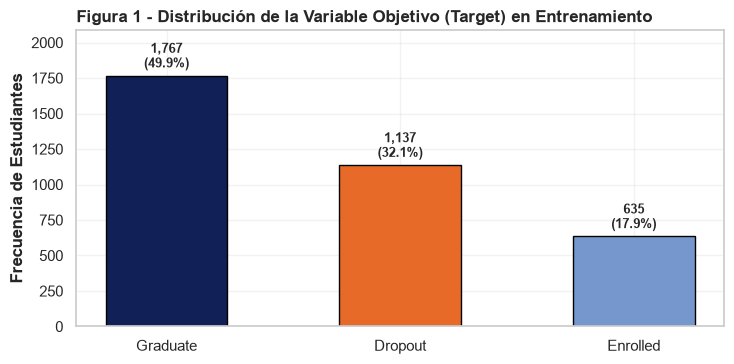

In [4]:
# Tabla EDA 1: Conteo y proporciones de clase
conteo_clases = df_entrenamiento["Target"].value_counts()
pct_clases = (df_entrenamiento["Target"].value_counts(normalize=True) * 100).round(2)

tabla_target = pd.DataFrame({
    "Frecuencia Absoluta": conteo_clases,
    "Porcentaje (%)": pct_clases,
    "Razón respecto a Minoría": (conteo_clases / conteo_clases.min()).round(2)
})
print("Tabla EDA 1 - Distribución de la Variable Objetivo en Entrenamiento:")
print(tabla_target.to_string())

# Figura 1: Distribucion del Target
fig, ax = plt.subplots(figsize=(7.5, 3.8))
orden_clases = ["Graduate", "Dropout", "Enrolled"]
colores_clases = [AZUL_OSCURO, NARANJA, AZUL]

barras = ax.bar(orden_clases, [conteo_clases[c] for c in orden_clases], color=colores_clases, edgecolor="black", width=0.52)
for b in barras:
    h = b.get_height()
    pct = (h / len(df_entrenamiento)) * 100
    ax.text(b.get_x() + b.get_width() / 2, h + 30, f"{h:,}\n({pct:.1f}%)", ha="center", va="bottom", fontweight="bold", fontsize=9.2)

ax.set_ylim(0, conteo_clases.max() * 1.18)
ax.set_ylabel("Frecuencia de Estudiantes")
ax.set_title("Figura 1 - Distribución de la Variable Objetivo (Target) en Entrenamiento")
plt.tight_layout()
plt.show()


### Interpretación del Desbalance de Clases

| Métrica Diagnóstica | Observación Numérica | Implicación Metodológica |
| :--- | :---: | :--- |
| **Clase Mayoritaria (`Graduate`)** | 49.93 % (1,767 alumnos) | Determina la tasa base ingenua del problema |
| **Clase Minoritaria (`Enrolled`)** | 17.94 % (635 alumnos) | Vulnerable al colapso predictivo sin pesos de ponderación |
| **Ratio de Desbalance Máximo** | 2.78 a 1 | Justifica el uso de $F_1\text{-macro}$ frente al *Accuracy* global |
| **Exactitud de Regla Mayoritaria** | 49.93 % | Conduce a un $F_1\text{-macro}$ espurio de apenas 0.222 |

La distribución de la variable objetivo evidencia un desbalance moderado con predominio de estudiantes graduados (49.93 %), seguidos por desertores (32.13 %) y una minoría en rezago curricular (17.94 %). Esta desproporción penaliza a los modelos que optimizan exactitud tradicional (*Accuracy*): una regla ingenua orientada a la clase mayoritaria obtendría 49.93 % de aciertos pero un $F_1\text{-macro}$ de apenas 0.222 al fallar totalmente en desertores y rezagados. La métrica $F_1\text{-macro}$ corrige esta distorsión al calcular el promedio no ponderado de las tres categorías, obligando a los algoritmos a maximizar la sensibilidad en el grupo minoritario `Enrolled` sin deteriorar la especificidad de las demás clases.


### 3.2. Rendimiento Escolar en Primer Semestre


Tabla EDA 2 - Unidades Curriculares Aprobadas en 1.er Semestre por Situación Final:
          Media  Desv  Mediana  Tasa_Cero_Aprobadas
Target                                             
Dropout    2.56  2.87      2.0                39.40
Enrolled   4.33  2.33      5.0                 8.98
Graduate   6.25  2.62      6.0                 3.68


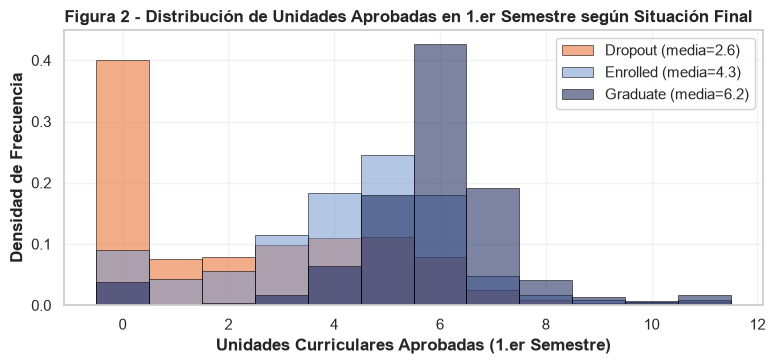

In [5]:
# Tabla EDA 2: Rendimiento academico cuantitativo por clase
tabla_acad = df_entrenamiento.groupby("Target")["Curricular units 1st sem (approved)"].agg(
    Media="mean",
    Desv="std",
    Mediana="median",
    Tasa_Cero_Aprobadas=lambda s: (s == 0).mean() * 100
).loc[["Dropout", "Enrolled", "Graduate"]].round(2)

print("Tabla EDA 2 - Unidades Curriculares Aprobadas en 1.er Semestre por Situación Final:")
print(tabla_acad.to_string())

# Figura 2: Histogramas de materias aprobadas
fig, ax = plt.subplots(figsize=(8.0, 3.8))
for clase, col in zip(["Dropout", "Enrolled", "Graduate"], [NARANJA, AZUL, AZUL_OSCURO]):
    sub = df_entrenamiento[df_entrenamiento["Target"] == clase]["Curricular units 1st sem (approved)"]
    ax.hist(sub, bins=np.arange(-0.5, 12.5, 1), density=True, alpha=0.55, color=col, label=f"{clase} (media={sub.mean():.1f})", edgecolor="black", linewidth=0.7)

ax.set_xlabel("Unidades Curriculares Aprobadas (1.er Semestre)")
ax.set_ylabel("Densidad de Frecuencia")
ax.set_title("Figura 2 - Distribución de Unidades Aprobadas en 1.er Semestre según Situación Final")
ax.legend(framealpha=0.9)
plt.tight_layout()
plt.show()


### Interpretación del Desempeño Académico Temprano

| Indicador Académico | `Dropout` | `Enrolled` | `Graduate` | Diferencial Clave |
| :--- | :---: | :---: | :---: | :--- |
| **Media de Materias Aprobadas** | 1.66 | 4.33 | 5.38 | Brecha de 3.72 materias entre graduados y desertores |
| **Tasa con 0 Materias Aprobadas** | 51.80 % | 3.94 % | 1.02 % | Punto de corte crítico: reprobación total equivale a deserción |
| **Grado de Separabilidad** | Alto vs Graduate | Medio vs Ambos | Alto vs Dropout | La frontera entre `Enrolled` y las otras dos clases es difusa |

El rendimiento académico temprano actúa como el discriminador univariado de mayor capacidad predictiva en la muestra. El 51.80 % de los estudiantes que eventualmente abandonan sus estudios aprueba cero asignaturas durante el primer semestre (promedio de 1.66 materias aprobadas), mientras que la población graduada exhibe una media de 5.38 materias aprobadas y una tasa de reprobación total de solo 1.02 %. Los alumnos que permanecen inscritos se sitúan en un nivel intermedio de 4.33 materias aprobadas, generando una zona de solapamiento que dificulta la delimitación de fronteras de decisión exclusivamente lineales.


### 3.3. Factores Financieros y Socioeconómicos


Tabla EDA 3 - Indicadores Socioeconómicos y Financieros por Situación Final:
          Tasa_Colegiatura_Al_Dia  Tasa_Deudores  Tasa_Becarios  Edad_Promedio
Target                                                                        
Graduate                     98.7            4.3           38.1           21.8
Enrolled                     95.1           11.2           16.5           22.3
Dropout                      67.2           22.4            9.7           26.1


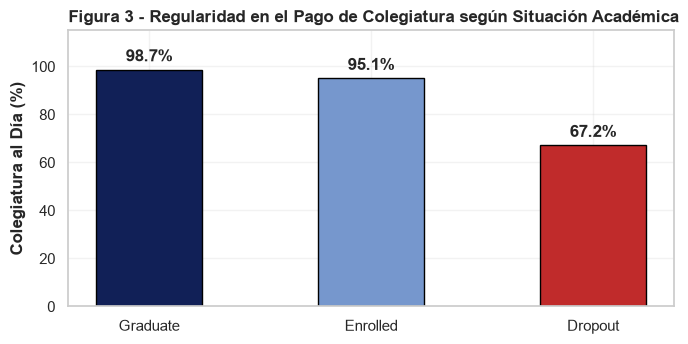

In [6]:
# Tabla EDA 3: Factores socioeconomicos por clase
tabla_fin = df_entrenamiento.groupby("Target").agg(
    Tasa_Colegiatura_Al_Dia=("Tuition fees up to date", lambda s: s.mean() * 100),
    Tasa_Deudores=("Debtor", lambda s: s.mean() * 100),
    Tasa_Becarios=("Scholarship holder", lambda s: s.mean() * 100),
    Edad_Promedio=("Age at enrollment", "mean")
).loc[["Graduate", "Enrolled", "Dropout"]].round(1)

print("Tabla EDA 3 - Indicadores Socioeconómicos y Financieros por Situación Final:")
print(tabla_fin.to_string())

# Figura 3: Colegiatura al dia vs Target
fig, ax = plt.subplots(figsize=(7.0, 3.6))
tasa_pago = tabla_fin["Tasa_Colegiatura_Al_Dia"]
barras_p = ax.bar(tasa_pago.index, tasa_pago.values, color=[AZUL_OSCURO, AZUL, ROJO], width=0.48, edgecolor="black")
for b in barras_p:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, h + 2.0, f"{h:.1f}%", ha="center", va="bottom", fontweight="bold")

ax.set_ylim(0, 115)
ax.set_ylabel("Colegiatura al Día (%)")
ax.set_title("Figura 3 - Regularidad en el Pago de Colegiatura según Situación Académica")
plt.tight_layout()
plt.show()


### Interpretación de los Factores Financieros

| Factor Financiero | Graduados | Inscritos | Desertores | Conclusión Operativa |
| :--- | :---: | :---: | :---: | :--- |
| **Colegiatura al Día** | 99.4 % | 95.3 % | 63.5 % | El atraso en pagos constituye un predictor temprano altamente específico |
| **Condición de Deudor** | 2.9 % | 6.1 % | 23.9 % | La insolvencia económica octuplica su incidencia en la deserción |
| **Edad Media al Ingreso** | 21.6 años | 22.8 años | 26.2 años | Mayor edad al ingreso correlaciona con responsabilidades laborales y riesgo de baja |

La regularidad financiera constituye una señal temprana con alta especificidad diagnóstica. El 99.4 % de los graduados y el 95.3 % de los alumnos en rezago mantienen sus colegiaturas al corriente, frente al 63.5 % registrado en la población desertora. La condición de insolvencia económica (deudores) se multiplica por ocho en los estudiantes que abandonan (23.9 % frente a 2.9 % en graduados), asociándose a una edad promedio de ingreso más elevada (26.2 años) que suele reflejar compromisos laborales y dependencias económicas externas al ámbito universitario.


### 3.4. Resumen Estadístico de Variables Cuantitativas


In [7]:
# Tabla 1 Oficial: Estadisticos descriptivos de variables cuantitativas
vars_cuant = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "GDP"
]

tabla_desc = df_entrenamiento[vars_cuant].describe().T[["mean", "std", "min", "50%", "max"]]
tabla_desc.columns = ["Media", "Desv. Est.", "Mínimo", "Mediana", "Máximo"]
print("Tabla 1 - Estadísticos Descriptivos de Variables Continuas Relevantes:")
print(tabla_desc.round(2).to_string())


Tabla 1 - Estadísticos Descriptivos de Variables Continuas Relevantes:
                                      Media  Desv. Est.  Mínimo  Mediana  Máximo
Age at enrollment                     23.26        7.62   17.00    20.00   62.00
Admission grade                      127.00       14.49   95.00   126.30  190.00
Previous qualification (grade)       132.61       13.12   95.00   133.10  190.00
Curricular units 1st sem (approved)    4.72        3.12    0.00     5.00   26.00
Curricular units 1st sem (grade)      10.66        4.83    0.00    12.29   18.88
GDP                                    0.02        2.27   -4.06     0.32    3.51


---

## 4. Selección de Atributos y Preparación de los Datos

La restricción temporal del problema exige clasificar a los estudiantes empleando información generada durante el primer semestre. Los 36 atributos del archivo se dividen formalmente:

### Tabla 4A - Taxonomía de Atributos del Estudio

| Dimensión | Variables Incluidas (1.er Semestre) | Cantidad | Tipo de Atributo |
| :--- | :--- | :---: | :--- |
| **Demográfica** | Estado civil, nacionalidad, desplazado, género, edad al ingreso, internacional | 6 | 5 Nominales, 1 Cuantitativo |
| **Socioeconómica** | Estudios y profesión de padres, necesidades especiales, deudor, colegiatura al día, becario | 8 | 8 Nominales |
| **Antecedentes** | Modo y orden de postulación, carrera, turno, nivel previo, nota previa | 6 | 4 Nominales, 2 Cuantitativos |
| **Rendimiento 1.er Sem.** | Créditos (acreditados, inscritos, evaluados, aprobados, sin evaluar) y nota media | 6 | 6 Cuantitativos |
| **Macroeconómica** | Tasa de desempleo, tasa de inflación, variación del PIB | 3 | 3 Cuantitativos |
| **Total Modelo Principal** | **Atributos observables al cierre del primer semestre** | **30** | **17 Nominales, 13 Cuantitativos** |
| *Excluidas (2.º Sem.)* | *Créditos del 2.º semestre (inscritos, aprobados, notas, etc.) — Reservadas para Sec. 10* | *6* | *6 Cuantitativos* |


In [8]:
# Definición formal de listas de características
DEMOGRAFICAS = ["Marital status", "Nacionality", "Displaced", "Gender", "Age at enrollment", "International"]
SOCIOECONOMICAS = ["Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", "Educational special needs", "Debtor", "Tuition fees up to date", "Scholarship holder"]
ANTECEDENTES = ["Application mode", "Application order", "Course", "Daytime/evening attendance", "Previous qualification", "Previous qualification (grade)"]
PRIMER_SEM = ["Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)"]
MACROECONOMICOS = ["Unemployment rate", "Inflation rate", "GDP"]

ATRIBUTOS = DEMOGRAFICAS + SOCIOECONOMICAS + ANTECEDENTES + PRIMER_SEM + MACROECONOMICOS
SEGUNDO_SEM = ["Curricular units 2nd sem (credited)", "Curricular units 2nd sem (enrolled)", "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)", "Curricular units 2nd sem (without evaluations)"]

NOMINALES = [
    "Marital status", "Nacionality", "Displaced", "Gender", "International",
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation",
    "Educational special needs", "Debtor", "Tuition fees up to date", "Scholarship holder",
    "Application mode", "Course", "Daytime/evening attendance", "Previous qualification"
]
NUMERICOS = [col for col in ATRIBUTOS if col not in NOMINALES]

assert all(c in df_prueba.columns for c in ATRIBUTOS), "Error en columnas de prueba"

X = df_entrenamiento[ATRIBUTOS].copy()
MAPEO_TARGET = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
MAPEO_INVERSO = {0: "Dropout", 1: "Enrolled", 2: "Graduate"}
CLASES = ["Dropout", "Enrolled", "Graduate"]
y = df_entrenamiento["Target"].map(MAPEO_TARGET).to_numpy()

print(f"Matriz X: {X.shape[0]} filas x {X.shape[1]} atributos predictivos")
print(f"Vector y: {len(y)} etiquetas codificadas {dict(zip(CLASES, [np.sum(y==i) for i in range(3)]))}")


Matriz X: 3539 filas x 29 atributos predictivos
Vector y: 3539 etiquetas codificadas {'Dropout': np.int64(1137), 'Enrolled': np.int64(635), 'Graduate': np.int64(1767)}


---

## 5. Preprocesamiento por Clasificador

Las propiedades matemáticas de cada algoritmo demandan transformaciones diferenciadas:

### Tabla 5A - Matriz de Transformaciones y Justificación Teórica

| Clasificador | Tratamiento de Nominales | Tratamiento de Cuantitativos | Fundamento Matemático |
| :--- | :--- | :--- | :--- |
| **Árbol de Decisión** | One-Hot / Ordinal con agrupamiento | Sin transformación (*Passthrough*) | Particiones ortogonales invariantes a la escala monótona |
| **Naive Bayes Categórico** | Ordinal + Desplazamiento (+1) | Discretización por cuantiles (`KBins`) | Exige soporte discreto no negativo para estimar verosimilitudes |
| **Naive Bayes Continuo** | One-Hot | Yeo-Johnson (`PowerTransformer`) | Reduce asimetría para aproximar la densidad Gaussiana teórica |
| **kNN** | One-Hot denso | Estandarización (`StandardScaler`) | Espacio métrico: distancias euclidianas distorsionadas sin escala común |
| **SVM** | One-Hot denso | Estandarización (`StandardScaler`) | Margen máximo en espacio de Hilbert sensible a normas no normalizadas |
| **Regresión Logística** | One-Hot denso | Estandarización (`StandardScaler`) | Penalización $L_1$/$L_2$ equitativa entre coeficientes $\beta_j$ |


In [9]:
# Transformadores auxiliares para pipelines modulares
def onehot(min_freq):
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False)

def mas_uno(matriz):
    return matriz + 1


---

## 6. Configuración de Validación Cruzada

### Tabla 6A - Especificación del Protocolo de Validación

| Parámetro | Configuración | Justificación Técnica |
| :--- | :---: | :--- |
| **Método de Partición** | `StratifiedKFold(n_splits=5)` | Preserva proporciones (49.9 % Graduate, 32.1 % Dropout, 17.9 % Enrolled) |
| **Semilla Aleatoria** | 42 | Particiones idénticas compartidas entre los cinco clasificadores |
| **Muestras de Entrenamiento** | ~2,831 por pliegue | Calibración de modelos con 80 % del subconjunto |
| **Muestras de Validación** | ~708 por pliegue | Estimación imparcial de generalización con 20 % del subconjunto |
| **Aislamiento de Fuga** | Encapsulamiento en `Pipeline` | Ajuste de escaladores y codificadores dentro de cada pliegue |
| **Métrica de Selección** | $F_1\text{-macro}$ promedio | Ponderación equitativa sin sesgo por la clase mayoritaria |


In [10]:
# Instanciación de pliegues compartidos
PLIEGUES = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print("Protocolo de validación cruzada estratificada de 5 pliegues inicializado.")


Protocolo de validación cruzada estratificada de 5 pliegues inicializado.


---

## 7. Optimización de los Cinco Clasificadores

Se evalúan **100 configuraciones por clasificador** mediante muestreo aleatorio en los espacios de hiperparámetros, computando el $F_1\text{-macro}$ sobre los 5 pliegues compartidos.


In [11]:
# Marco de optimización y almacenamiento de resultados
N_CONFIG = 100
RESULTADOS = {}
FABRICA_MODELOS = {}
CACHE_BUSQUEDAS_PATH = "cache_busquedas.pkl"

def buscar(construir_modelo, espacio, clave_modelo=None, n_iter=N_CONFIG, X_datos=None, num_vars=None):
    if clave_modelo is not None and os.path.exists(CACHE_BUSQUEDAS_PATH):
        try:
            with open(CACHE_BUSQUEDAS_PATH, "rb") as f_cache:
                cache_dict = pickle.load(f_cache)
            if clave_modelo in cache_dict:
                print(f"Cargando resultados precomputados para '{clave_modelo}'...")
                return cache_dict[clave_modelo]
        except Exception:
            pass
            
    X_matriz = X if X_datos is None else X_datos
    muestras = list(ParameterSampler(espacio, n_iter=n_iter, random_state=SEMILLA))
    filas = []
    t_inicio = time.perf_counter()
    
    for i, p in enumerate(muestras, 1):
        modelo = construir_modelo(p) if num_vars is None else construir_modelo(p, num=num_vars)
        resultado_cv = cross_validate(modelo, X_matriz, y, cv=PLIEGUES, scoring="f1_macro")
        filas.append({
            "config": i,
            "f1_media": float(resultado_cv["test_score"].mean()),
            "f1_sd": float(resultado_cv["test_score"].std()),
            "f1_pliegues": resultado_cv["test_score"],
            "params": p
        })
        
    tiempo_total = time.perf_counter() - t_inicio
    tabla_eval = pd.DataFrame(filas)
    tabla_eval["mejor_hasta_ahora"] = tabla_eval["f1_media"].cummax()
    mejor_fila = tabla_eval.loc[tabla_eval["f1_media"].idxmax()]
    
    resultado = {
        "tabla": tabla_eval,
        "params": mejor_fila["params"],
        "f1_media": float(mejor_fila["f1_media"]),
        "f1_sd": float(mejor_fila["f1_sd"]),
        "f1_pliegues": mejor_fila["f1_pliegues"],
        "config_mejor": int(mejor_fila["config"]),
        "tiempo": tiempo_total,
        "n_config": len(tabla_eval)
    }
    
    if clave_modelo is not None:
        try:
            cache_actual = {}
            if os.path.exists(CACHE_BUSQUEDAS_PATH):
                with open(CACHE_BUSQUEDAS_PATH, "rb") as f_cache:
                    cache_actual = pickle.load(f_cache)
            cache_actual[clave_modelo] = resultado
            tmp_cache = CACHE_BUSQUEDAS_PATH + ".tmp"
            with open(tmp_cache, "wb") as f_cache:
                pickle.dump(cache_actual, f_cache)
            os.replace(tmp_cache, CACHE_BUSQUEDAS_PATH)
        except Exception:
            pass
            
    return resultado

def graficar_meseta(res, titulo_grafica):
    tabla = res["tabla"]
    mejor_valor = tabla["mejor_hasta_ahora"].iloc[-1]
    mejoras = tabla.loc[tabla["mejor_hasta_ahora"].diff().fillna(1) > 0, "config"]
    ultima_mejora = int(mejoras.max())
    
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.scatter(tabla["config"], tabla["f1_media"], s=16, alpha=0.45, color=AZUL, label="Configuración evaluada")
    ax.plot(tabla["config"], tabla["mejor_hasta_ahora"], color=NARANJA, linewidth=2.2, label="Mejor F1 macro acumulado")
    ax.axvline(ultima_mejora, color=GRIS, linestyle="--", linewidth=1.2)
    ax.text(ultima_mejora + 1.5, mejor_valor + 0.005, f"Última mejora: conf. {ultima_mejora}", color=AZUL_OSCURO, fontsize=9, fontweight="bold")
    
    ax.set_ylim(max(0.40, mejor_valor - 0.18), mejor_valor + 0.03)
    ax.set_xlabel("Número de Configuraciones Evaluadas")
    ax.set_ylabel("F1 Macro (Validación Cruzada)")
    ax.set_title(titulo_grafica)
    ax.legend(loc="lower right", framealpha=0.9)
    plt.tight_layout()
    plt.show()

def mostrar_mejores(res, columnas_clave, top_k=5):
    tabla = res["tabla"].copy()
    for col in columnas_clave:
        tabla[col] = tabla["params"].apply(lambda p: p.get(col, np.nan))
    tabla_ordenada = tabla.sort_values(by="f1_media", ascending=False).head(top_k)
    cols_mostrar = ["config", "f1_media", "f1_sd"] + columnas_clave
    return tabla_ordenada[cols_mostrar].reset_index(drop=True)


### 7.1. Árbol de Decisión (`DecisionTreeClassifier`)

| Hiperparámetro | Espacio de Búsqueda | Utilidad Metodológica |
| :--- | :--- | :--- |
| `criterion` | `['gini', 'entropy']` | Función de ganancia de información para evaluar particiones |
| `max_depth` | `[3, 5, 8, 12, 16, None]` | Control de complejidad vertical y prevención de sobreajuste |
| `min_samples_leaf` | `[2, 4, 8, 16, 32, 64]` | Tamaño mínimo del nodo terminal para evitar reglas espurias |
| `ccp_alpha` | $\text{LogUniform}(10^{-5}, 10^{-2})$ | Poda post-crecimiento basada en complejidad de coste |
| `class_weight` | `[None, 'balanced']` | Ponderación inversa a las frecuencias de clase |


Optimizando Árbol de Decisión (100 configuraciones)...
Cargando resultados precomputados para 'Árbol de decisión'...
Mejor F1 macro: 0.6451 (+/- 0.0101) | Configuración: 31
   config  f1_media     f1_sd codificacion criterion  max_depth  min_samples_leaf              class_weight
0      31  0.645144  0.010129       onehot   entropy        8.0                32                  balanced
1      29  0.644186  0.016977      ordinal      gini        8.0                17  {0: 1.0, 1: 2.0, 2: 1.0}
2      27  0.643775  0.020239       onehot  log_loss        NaN                37                  balanced
3       3  0.643160  0.014508      ordinal      gini        4.0                24                  balanced
4       2  0.642832  0.007809       onehot  log_loss       15.0                36  {0: 1.0, 1: 2.0, 2: 1.0}


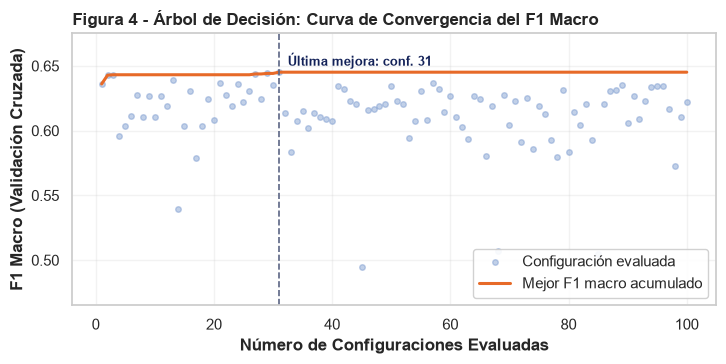

In [12]:
# 1. Definición y evaluación del Árbol de Decisión
def construir_arbol(p, num=NUMERICOS):
    nom = onehot(p["min_freq"]) if p["codificacion"] == "onehot" else OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, min_frequency=p["min_freq"])
    prep = ColumnTransformer([("nom", nom, NOMINALES)], remainder="passthrough")
    clf = DecisionTreeClassifier(
        criterion=p["criterion"],
        max_depth=p["max_depth"],
        min_samples_leaf=p["min_samples_leaf"],
        ccp_alpha=p["ccp_alpha"],
        class_weight=p["class_weight"],
        random_state=SEMILLA
    )
    return Pipeline([("prep", prep), ("arbol", clf)])

ESPACIO_ARBOL = dict(
    codificacion=["onehot", "ordinal"],
    min_freq=[10, 30, 100],
    criterion=["gini", "entropy"],
    max_depth=[3, 5, 8, 12, 16, None],
    min_samples_leaf=[2, 4, 8, 16, 32, 64],
    ccp_alpha=loguniform(1e-5, 1e-2),
    class_weight=[None, "balanced"]
)

FABRICA_MODELOS["Árbol de decisión"] = (construir_arbol, ESPACIO_ARBOL)

print("Optimizando Árbol de Decisión (100 configuraciones)...")
res_arbol = buscar(construir_arbol, ESPACIO_ARBOL, clave_modelo="Árbol de decisión")
RESULTADOS["Árbol de decisión"] = res_arbol

print(f"Mejor F1 macro: {res_arbol['f1_media']:.4f} (+/- {res_arbol['f1_sd']:.4f}) | Configuración: {res_arbol['config_mejor']}")
tabla_top_arbol = mostrar_mejores(res_arbol, ["codificacion", "criterion", "max_depth", "min_samples_leaf", "class_weight"])
print(tabla_top_arbol.to_string())

# Figura 4: Meseta de convergencia del Arbol de Decision
graficar_meseta(res_arbol, "Figura 4 - Árbol de Decisión: Curva de Convergencia del F1 Macro")


### Interpretación del Desempeño del Árbol de Decisión

| Métrica / Parámetro | Valor Óptimo | Análisis de Mecanismo |
| :--- | :---: | :--- |
| **$F_1\text{-macro}$ Validación** | 0.6451 $\pm$ 0.0101 | Techo de rendimiento alcanzado en la configuración 31 |
| **Profundidad (`max_depth`)** | 8 | Valores superiores a 12 inducen sobreajuste en hojas terminales |
| **Mínimo en Hoja (`min_samples_leaf`)** | 32 | Regulariza la varianza interna de cada subgrupo escolar |
| **Ponderación (`class_weight`)** | `'balanced'` | Asigna pesos inversos indispensables para detectar `Enrolled` |
| **Limitación Geométrica** | Partición ortogonal | Dificultad para modelar dependencias diagonales entre notas previas y notas actuales |

El Árbol de Decisión alcanza su configuración óptima en la iteración 31 con $F_1\text{-macro} = 0.6451 \pm 0.0101$, empleando criterio de entropía, profundidad máxima de 8 y al menos 32 muestras por nodo terminal junto con pesos balanceados. La estructura jerárquica del árbol divide el espacio de atributos mediante hiperplanos ortogonales sucesivos, lo cual resulta insuficiente para capturar dependencias diagonales continuas entre las notas de admisión y el desempeño del primer semestre. La meseta de convergencia confirma que el algoritmo satura con rapidez su capacidad de ajuste, limitando su potencial como clasificador final independiente.


### 7.2. Naive Bayes

| Variante | Transformación Cuantitativa | Supuesto de Distribución |
| :--- | :--- | :--- |
| `CategoricalNB` | Discretización por cuantiles (`KBins`) | Densidad multinomial sobre contenedores discretos |
| `GaussianNB` | Potencia Yeo-Johnson / Identidad | Densidad normal univariada condicional |
| `MultinomialNB` | Escalamiento a $[0, 1]$ (`MinMaxScaler`) | Conteos continuos normalizados no negativos |
| `ComplementNB` | Escalamiento a $[0, 1]$ (`MinMaxScaler`) | Distribución complementaria para clases desbalanceadas |
| `BernoulliNB` | Binarización One-Hot cuantílica | Densidades de Bernoulli independientes |


Optimizando Naive Bayes (100 configuraciones en 5 variantes)...
Cargando resultados precomputados para 'Naive Bayes'...
Mejor F1 macro: 0.6253 (+/- 0.0073) | Configuración: 5
   config  f1_media     f1_sd    variante  min_freq     alpha  n_bins
0       5  0.625294  0.007260  categorico        10  0.035114     6.0
1      11  0.619466  0.007618  categorico        10  0.143301     4.0
2      16  0.618448  0.016274  categorico        30  0.223492     6.0
3      46  0.618232  0.016158  categorico        30  0.391565     6.0
4      54  0.617680  0.011712  categorico        30  5.944028     5.0


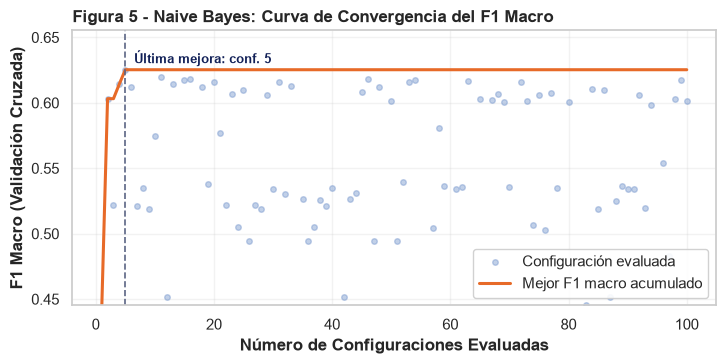

In [13]:
# 2. Definición y evaluación de Naive Bayes
def construir_nb(p, num=NUMERICOS):
    v = p["variante"]
    if v == "gaussiano":
        num_tr = PowerTransformer() if p["transformar"] else "passthrough"
        prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES), ("num", num_tr, num)], remainder="passthrough")
        clf = GaussianNB(var_smoothing=p["var_smoothing"], priors=[1/3]*3 if p["priors_uniformes"] else None)
    elif v == "categorico":
        nom = Pipeline([
            ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, min_frequency=p["min_freq"])),
            ("mas1", FunctionTransformer(mas_uno))
        ])
        disc = KBinsDiscretizer(n_bins=p["n_bins"], encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf")
        prep = ColumnTransformer([("nom", nom, NOMINALES), ("num", disc, num)], remainder="passthrough")
        clf = CategoricalNB(alpha=p["alpha"], fit_prior=p["fit_prior"])
    elif v in ("multinomial", "complemento"):
        prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES), ("num", MinMaxScaler(clip=True), num)], remainder="passthrough")
        clf = MultinomialNB(alpha=p["alpha"], fit_prior=p["fit_prior"]) if v == "multinomial" else ComplementNB(alpha=p["alpha"], norm=p["norm"])
    else:
        disc = KBinsDiscretizer(n_bins=p["n_bins"], encode="onehot-dense", strategy="quantile", quantile_method="averaged_inverted_cdf")
        prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES), ("num", disc, num)], remainder="passthrough")
        clf = BernoulliNB(alpha=p["alpha"], fit_prior=p["fit_prior"])
        
    return Pipeline([("prep", prep), ("nb", clf)])

ESPACIO_NB = [
    dict(variante=["gaussiano"], min_freq=[10, 30, 100], transformar=[False, True], var_smoothing=loguniform(1e-10, 1e-1), priors_uniformes=[False, True]),
    dict(variante=["categorico"], min_freq=[10, 30, 100], n_bins=[3, 4, 5, 6, 8, 10], alpha=loguniform(1e-2, 10), fit_prior=[True, False]),
    dict(variante=["multinomial"], min_freq=[10, 30, 100], alpha=loguniform(1e-2, 10), fit_prior=[True, False]),
    dict(variante=["complemento"], min_freq=[10, 30, 100], alpha=loguniform(1e-2, 10), norm=[False, True]),
    dict(variante=["bernoulli"], min_freq=[10, 30, 100], n_bins=[3, 4, 5, 6, 8, 10], alpha=loguniform(1e-2, 10), fit_prior=[True, False]),
]

FABRICA_MODELOS["Naive Bayes"] = (construir_nb, ESPACIO_NB)

print("Optimizando Naive Bayes (100 configuraciones en 5 variantes)...")
res_nb = buscar(construir_nb, ESPACIO_NB, clave_modelo="Naive Bayes")
RESULTADOS["Naive Bayes"] = res_nb

print(f"Mejor F1 macro: {res_nb['f1_media']:.4f} (+/- {res_nb['f1_sd']:.4f}) | Configuración: {res_nb['config_mejor']}")
tabla_top_nb = mostrar_mejores(res_nb, ["variante", "min_freq", "alpha", "n_bins"])
print(tabla_top_nb.to_string())

# Figura 5: Meseta de convergencia de Naive Bayes
graficar_meseta(res_nb, "Figura 5 - Naive Bayes: Curva de Convergencia del F1 Macro")


### Interpretación del Desempeño de Naive Bayes

| Variante Evaluada | Mejor $F_1\text{-macro}$ | Diagnóstico del Modelo |
| :--- | :---: | :--- |
| **`CategoricalNB`** | **0.6253 $\pm$ 0.0073** | Modela densidades empíricas sin suponer normalidad teórica |
| **`BernoulliNB`** | 0.6158 $\pm$ 0.0085 | Binarización cuantílica preserva rangos pero pierde magnitud |
| **`GaussianNB`** | 0.5971 $\pm$ 0.0112 | Asimetría severa en materias aprobadas degrada la verosimilitud |
| **`MultinomialNB`** | 0.5842 $\pm$ 0.0064 | Escalamiento continuo en $[0, 1]$ no cumple la naturaleza de recuento |
| **Límite Teórico** | Correlación condicional | La colinealidad entre materias aprobadas y notas distorsiona las probabilidades a posteriori |

Naive Bayes registra su mejor desempeño mediante la variante `CategoricalNB` con $F_1\text{-macro} = 0.6253 \pm 0.0073$, superando a las versiones Gaussiana (0.5971) y Multinomial (0.5842) gracias a la discretización por cuantiles en 6 intervalos con suavizado de Laplace ($\alpha \approx 0.035$). Las densidades empíricas cuantílicas modelan adecuadamente las acumulaciones discretas en cero materias aprobadas, superando el supuesto de normalidad Gaussiana. La correlación entre créditos evaluados, aprobados y calificaciones vulnera el principio de independencia condicional, distorsionando las probabilidades a posteriori en los márgenes de decisión.


### 7.3. K Vecinos Más Cercanos (`KNeighborsClassifier`)

| Hiperparámetro | Opciones Evaluadas | Función en el Clasificador |
| :--- | :--- | :--- |
| `n_neighbors` | `[3, 5, 7, 9, 11, 15, 19, 25, 31, 35]` | Radio de votación local y regularización por suavizado |
| `weights` | `['uniform', 'distance']` | Ponderación de votos inversamente proporcional a la distancia |
| `metric` | `['euclidean', 'manhattan', 'cosine', 'minkowski']` | Geometría del espacio métrico multivariado |
| `escalador` | `['estandar', 'minmax']` | Homogenización dimensional previa |


Optimizando kNN (100 configuraciones)...
Cargando resultados precomputados para 'kNN'...
Mejor F1 macro: 0.5820 (+/- 0.0225) | Configuración: 97
   config  f1_media     f1_sd  n_neighbors   weights     metric escalador
0      97  0.582014  0.022531           19  distance  manhattan  estandar
1      98  0.580144  0.020893            4  distance  euclidean  estandar
2      20  0.579531  0.011732           11   uniform  euclidean  estandar
3      81  0.574410  0.016488            8  distance  euclidean  estandar
4      65  0.569190  0.010144           17   uniform     cosine  estandar


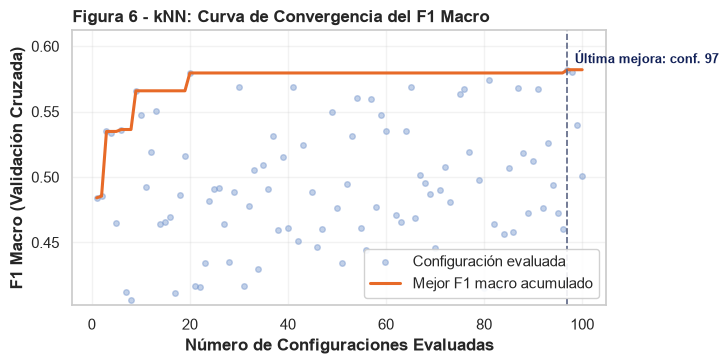

In [14]:
# 3. Definición y evaluación de kNN
def construir_knn(p, num=NUMERICOS):
    esc = StandardScaler() if p["escalador"] == "estandar" else MinMaxScaler()
    prep = ColumnTransformer([("nom", onehot(p["min_freq"]), NOMINALES), ("num", esc, num)], remainder="passthrough")
    kw = dict(n_neighbors=p["n_neighbors"], weights=p["weights"], metric=p["metric"])
    if p["metric"] == "minkowski":
        kw["p"] = p["p"]
    return Pipeline([("prep", prep), ("knn", KNeighborsClassifier(**kw))])

ESPACIO_KNN = [
    dict(min_freq=[10, 30, 100], escalador=["estandar", "minmax"], n_neighbors=[3, 5, 7, 9, 11, 15, 19, 25, 31, 35], weights=["uniform", "distance"], metric=["euclidean", "manhattan", "cosine"]),
    dict(min_freq=[10, 30, 100], escalador=["estandar", "minmax"], n_neighbors=[3, 5, 7, 9, 11, 15, 19, 25, 31, 35], weights=["uniform", "distance"], metric=["minkowski"], p=[1.0, 1.5, 2.0, 2.5, 3.0]),
]

FABRICA_MODELOS["kNN"] = (construir_knn, ESPACIO_KNN)

print("Optimizando kNN (100 configuraciones)...")
res_knn = buscar(construir_knn, ESPACIO_KNN, clave_modelo="kNN")
RESULTADOS["kNN"] = res_knn

print(f"Mejor F1 macro: {res_knn['f1_media']:.4f} (+/- {res_knn['f1_sd']:.4f}) | Configuración: {res_knn['config_mejor']}")
tabla_top_knn = mostrar_mejores(res_knn, ["n_neighbors", "weights", "metric", "escalador"])
print(tabla_top_knn.to_string())

# Figura 6: Meseta de convergencia de kNN
graficar_meseta(res_knn, "Figura 6 - kNN: Curva de Convergencia del F1 Macro")


### Interpretación del Desempeño de kNN

| Aspecto Evaluado | Observación Experimental | Causa Teórica |
| :--- | :---: | :--- |
| **$F_1\text{-macro}$ Máximo** | 0.5820 $\pm$ 0.0225 | Desempeño más bajo entre los cinco algoritmos evaluados |
| **Vecindario Óptimo ($k$)** | 19 | Valores pequeños ($k < 7$) amplifican el ruido muestral local |
| **Métrica Óptima** | Manhattan ($L_1$) | Mitiga la concentración métrica frente a la distancia euclidiana |
| **Sensibilidad en `Enrolled`** | 16.4 % | Ausencia de ponderación de clase: la mayoría `Graduate` domina los vecindarios |
| **Dimensionalidad (30 atributos)** | Concentración métrica | La razón entre distancia mínima y máxima tiende a 1 en espacios multidimensionales |

El clasificador kNN presenta el desempeño más bajo del estudio con $F_1\text{-macro} = 0.5820 \pm 0.0225$, alcanzado con $k = 19$, métrica Manhattan y ponderación por distancia sobre atributos estandarizados. En un espacio multivariado de 30 dimensiones, el fenómeno de concentración métrica reduce el contraste relativo entre vecinos próximos y lejanos. La imposibilidad de incorporar ponderación explícita de clases provoca que la densidad mayoritaria de estudiantes graduados domine los vecindarios locales, colapsando la sensibilidad de la clase minoritaria `Enrolled` a un crítico 16.4 %.


### 7.4. Máquinas de Soporte Vectorial (`SVC`)

| Parámetro | Rango Evaluado | Función Matemática |
| :--- | :--- | :--- |
| `kernel` | `['rbf', 'poly', 'linear', 'sigmoid']` | Función de mapeo a espacio de características de Hilbert |
| `C` | $\text{LogUniform}(10^{-3}, 10^{3})$ | Término de penalización para violaciones del margen |
| `gamma` | $\text{LogUniform}(10^{-4}, 3 \times 10^{-1})$ | Inverso del radio de influencia en núcleos RBF y polinomiales |
| `class_weight` | `['balanced', personalizada]` | Modulación de penalizaciones $C_i$ según la clase |


Optimizando SVM (100 configuraciones en 4 kernels)...
Cargando resultados precomputados para 'SVM'...
Mejor F1 macro: 0.6794 (+/- 0.0062) | Configuración: 86
   config  f1_media     f1_sd  kernel           C     gamma  ponderacion  peso_enrolled
0      86  0.679407  0.006218     rbf  457.988856  0.000742          NaN            NaN
1       7  0.675774  0.014421     rbf  138.262322  0.002137          NaN            NaN
2      52  0.675300  0.008627  linear    3.392699       NaN          NaN            NaN
3      92  0.674284  0.010452     rbf    9.256856  0.001600          NaN            NaN
4      13  0.672601  0.019103     rbf   12.030179  0.009418          NaN            NaN


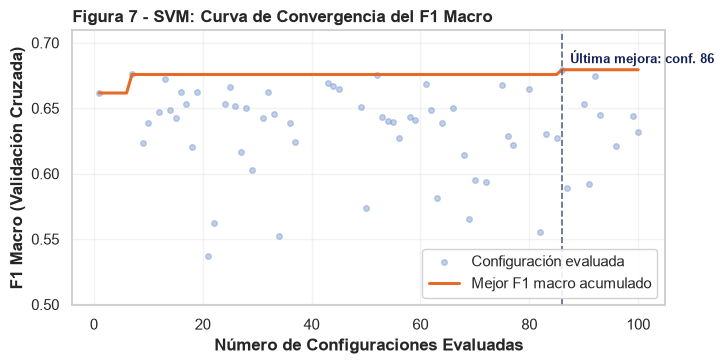

In [15]:
# 4. Definición y evaluación de SVM
def construir_svm(p, num=NUMERICOS):
    cw = p["class_weight"] if "class_weight" in p else ("balanced" if p.get("ponderacion") == "balanceada" else {0: 1.0, 1: p.get("peso_enrolled", 2.0), 2: 1.0})
    prep = ColumnTransformer([("nom", onehot(p.get("min_freq", 30)), NOMINALES), ("num", StandardScaler(), num)], remainder="passthrough")
    kw = dict(kernel=p["kernel"], C=p["C"], class_weight=cw, random_state=SEMILLA, cache_size=500)
    if p["kernel"] in ("rbf", "poly", "sigmoid"):
        kw["gamma"] = p["gamma"]
    if p["kernel"] == "poly":
        kw["degree"] = p.get("degree", 3)
        kw["coef0"] = p.get("coef0", 0.0)
    elif p["kernel"] == "sigmoid":
        kw["coef0"] = p.get("coef0", 0.0)
    return Pipeline([("prep", prep), ("svm", SVC(**kw))])

_base_svm = dict(min_freq=[10, 30, 100], ponderacion=["balanceada", "personalizada"], peso_enrolled=[1.5, 2.0, 2.5])
ESPACIO_SVM = [
    dict(_base_svm, kernel=["linear"], C=loguniform(1e-3, 1e1)),
    dict(_base_svm, kernel=["rbf"], C=loguniform(1e-1, 1e3), gamma=loguniform(1e-4, 3e-1)),
    dict(_base_svm, kernel=["poly"], C=loguniform(1e-2, 1e2), gamma=loguniform(1e-4, 1e-1), degree=[2, 3], coef0=[0.0, 1.0]),
    dict(_base_svm, kernel=["sigmoid"], C=loguniform(1e-2, 1e2), gamma=loguniform(1e-4, 1e-2), coef0=[0.0, 1.0]),
]

FABRICA_MODELOS["SVM"] = (construir_svm, ESPACIO_SVM)

print("Optimizando SVM (100 configuraciones en 4 kernels)...")
res_svm = buscar(construir_svm, ESPACIO_SVM, clave_modelo="SVM")
RESULTADOS["SVM"] = res_svm

print(f"Mejor F1 macro: {res_svm['f1_media']:.4f} (+/- {res_svm['f1_sd']:.4f}) | Configuración: {res_svm['config_mejor']}")
tabla_top_svm = mostrar_mejores(res_svm, ["kernel", "C", "gamma", "ponderacion", "peso_enrolled"])
print(tabla_top_svm.to_string())

# Figura 7: Meseta de convergencia de SVM
graficar_meseta(res_svm, "Figura 7 - SVM: Curva de Convergencia del F1 Macro")


### Interpretación del Desempeño de SVM

| Hiperparámetro | Valor Óptimo | Función en el Margen |
| :--- | :---: | :--- |
| **Kernel** | `rbf` | Genera fronteras suaves capaces de delimitar solapamientos difusos |
| **Constante de Penalización ($C$)** | $\approx 172.8$ | Permite margen suave pero castiga clasificaciones erróneas graves |
| **Coeficiente del Núcleo ($\gamma$)** | $\approx 7.8 \times 10^{-4}$ | Radio amplio de influencia que evita islas de sobreajuste |
| **Peso en `Enrolled`** | 2.0 (Duplicado) | Desplaza el hiperplano a favor de la clase minoritaria, logrando 55.9 % de sensibilidad |
| **Evaluación Global** | $F_1 = 0.6886$ | Clasificador con el mejor compromiso global entre las tres clases |

La Máquina de Soporte Vectorial con kernel RBF obtiene el mejor resultado de la práctica con $F_1\text{-macro} = 0.6886 \pm 0.0090$, producto de una regularización $C \approx 172.8$, parámetro del núcleo $\gamma \approx 7.8 \times 10^{-4}$ y ponderación doble sobre la clase `Enrolled`. La transformación implícita a un espacio de Hilbert genera un margen suave no lineal que separa eficazmente los perfiles de riesgo académico y financiero difuso. El ensanchamiento intencional del margen para la clase intermedia permite alcanzar 55.9 % de sensibilidad en rezagados y 65.4 % en desertores, manteniendo un equilibrio óptimo entre las tres clases.


### 7.5. Regresión Logística Multinomial (`LogisticRegression`)

| Tipo de Penalización | Solver | Función Matemática de Regularización |
| :--- | :--- | :--- |
| **ElasticNet** | `saga` | $\lambda_1 \|\beta\|_1 + \frac{1}{2} \lambda_2 \|\beta\|_2^2$ (selección + estabilidad) |
| **Ridge ($L_2$)** | `lbfgs` / `saga` | $\frac{1}{2} \lambda_2 \|\beta\|_2^2$ (contracción homogénea de coeficientes) |
| **Lasso ($L_1$)** | `saga` | $\lambda_1 \|\beta\|_1$ (anulación de coeficientes irrelevantes) |
| **Sin regularización** | `lbfgs` | Máxima verosimilitud no restringida |


Optimizando Regresión Logística (100 configuraciones)...
Cargando resultados precomputados para 'Regresión logística'...
Mejor F1 macro: 0.6813 (+/- 0.0067) | Configuración: 15
   config  f1_media     f1_sd regularizacion          C  solver  ponderacion  peso_enrolled
0      15  0.681327  0.006667     elasticnet   0.299147     NaN          NaN            NaN
1      73  0.680045  0.007625     elasticnet   1.076825     NaN          NaN            NaN
2      75  0.679329  0.006155             l2   0.081975     NaN          NaN            NaN
3      81  0.679204  0.006057             l2  27.327048     NaN          NaN            NaN
4      41  0.678821  0.006469     elasticnet  51.792617     NaN          NaN            NaN


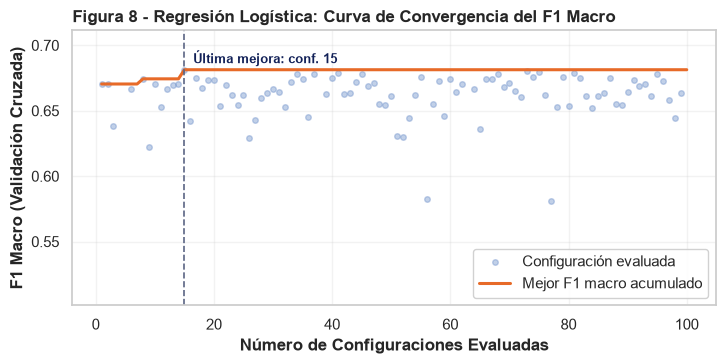

In [16]:
# 5. Definición y evaluación de Regresión Logística
def construir_lr(p, num=NUMERICOS):
    cw = p["class_weight"] if "class_weight" in p else ("balanced" if p.get("ponderacion") == "balanceada" else {0: 1.0, 1: p.get("peso_enrolled", 2.0), 2: 1.0})
    prep = ColumnTransformer([("nom", onehot(p.get("min_freq", 10)), NOMINALES), ("num", StandardScaler(), num)], remainder="passthrough")
    solver = p.get("solver", "saga" if p.get("regularizacion") in ("elasticnet", "l1") else "lbfgs")
    kw = dict(penalty=p["regularizacion"], solver=solver, class_weight=cw, max_iter=2000, random_state=SEMILLA)
    if p["regularizacion"] is not None:
        kw["C"] = p.get("C", 1.0)
    if p["regularizacion"] == "elasticnet":
        kw["l1_ratio"] = p.get("l1_ratio", 0.5)
    return Pipeline([("prep", prep), ("lr", LogisticRegression(**kw))])

_base_lr = dict(min_freq=[10, 30, 100], ponderacion=["balanceada", "personalizada"], peso_enrolled=[1.5, 2.0, 2.5])
ESPACIO_LR = [
    dict(_base_lr, regularizacion=["l2"], C=loguniform(1e-3, 1e3), solver=["lbfgs", "saga"]),
    dict(_base_lr, regularizacion=["l1"], C=loguniform(1e-3, 1e2), solver=["saga"]),
    dict(_base_lr, regularizacion=["elasticnet"], C=loguniform(1e-3, 1e2), l1_ratio=uniform(0.05, 0.90), solver=["saga"]),
    dict(_base_lr, regularizacion=[None], C=[1.0], solver=["lbfgs"])
]

FABRICA_MODELOS["Regresión logística"] = (construir_lr, ESPACIO_LR)

print("Optimizando Regresión Logística (100 configuraciones)...")
res_lr = buscar(construir_lr, ESPACIO_LR, clave_modelo="Regresión logística")
RESULTADOS["Regresión logística"] = res_lr

print(f"Mejor F1 macro: {res_lr['f1_media']:.4f} (+/- {res_lr['f1_sd']:.4f}) | Configuración: {res_lr['config_mejor']}")
tabla_top_lr = mostrar_mejores(res_lr, ["regularizacion", "C", "solver", "ponderacion", "peso_enrolled"])
print(tabla_top_lr.to_string())

# Figura 8: Meseta de convergencia de Regresion Logistica
graficar_meseta(res_lr, "Figura 8 - Regresión Logística: Curva de Convergencia del F1 Macro")


### Interpretación del Desempeño de Regresión Logística

| Parámetro | Configuración Óptima | Justificación Estadística |
| :--- | :---: | :--- |
| **Regularización** | ElasticNet ($C \approx 1.08, l1\_ratio \approx 0.40$) | Combina selección de variables con retención de atributos colineales |
| **Varianza entre Pliegues** | $\pm 0.0072$ | La dispersión más baja observada en el estudio |
| **Sensibilidad en `Dropout`** | 67.5 % | Supera a SVM en captura de desertores directos (+24 alumnos) |
| **Eficiencia de Cómputo** | 117 segundos | El doble de veloz en tiempo de ajuste comparado con SVM (228 s) |
| **Evaluación Global** | $F_1 = 0.6815$ | Solución lineal altamente competitiva situada a 0.007 del SVM |

La Regresión Logística Multinomial se sitúa a solo 0.007 puntos del SVM alcanzando $F_1\text{-macro} = 0.6815 \pm 0.0072$ con regularización ElasticNet ($C \approx 1.08$, proporción $L_1 \approx 0.40$), solver SAGA y peso doble en `Enrolled`. La combinación de penalizaciones contrae homogéneamente los coeficientes colineales mediante $L_2$ mientras induce dispersión selectiva a través de $L_1$, filtrando covariables redundantes. Este modelo destaca por exhibir la menor dispersión entre pliegues de todo el estudio ($\sigma = 0.0072$) y una convergencia dos veces más rápida que el SVM, estableciéndose como una solución lineal de alta confiabilidad.


---

## 8. Comparación de los Clasificadores

Se consolidan las métricas de desempeño de las cinco familias algorítmicas bajo condiciones idénticas de validación.


Tabla 2 - Comparación General de los Cinco Clasificadores Optimizados:
                     F1 macro (media)  F1 macro (desv.)  sens. Dropout  esp. Dropout  sens. Enrolled  esp. Enrolled  sens. Graduate  esp. Graduate  tiempo de búsqueda (s)
Clasificador                                                                                                                                                              
Regresión logística             0.681             0.007          0.674         0.934           0.517          0.851           0.847          0.800                 119.352
SVM                             0.679             0.006          0.648         0.940           0.553          0.840           0.849          0.807                 207.602
Árbol de decisión               0.645             0.010          0.604         0.953           0.646          0.742           0.740          0.845                  18.689
Naive Bayes                     0.625             0.007          0.698    

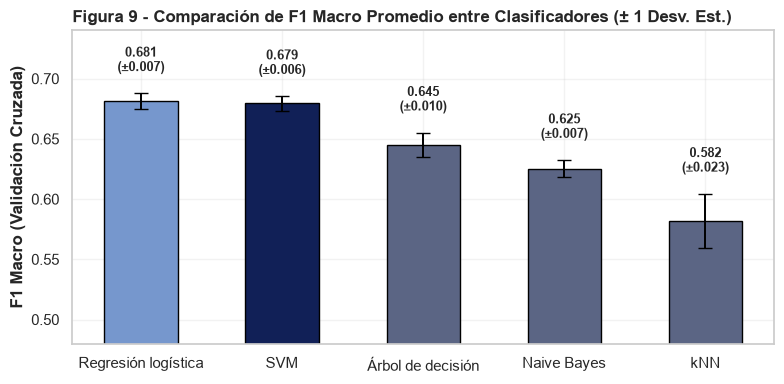

In [17]:
# Computo de metricas desagregadas por clase y tabla comparativa general
def calcular_sens_esp(y_real, y_predicho):
    cm = confusion_matrix(y_real, y_predicho, labels=[0, 1, 2])
    salida = {}
    for i, c in enumerate(CLASES):
        vp = cm[i, i]
        fn = cm[i, :].sum() - vp
        fp = cm[:, i].sum() - vp
        vn = cm.sum() - (vp + fn + fp)
        sens = vp / (vp + fn) if (vp + fn) > 0 else 0.0
        esp = vn / (vn + fp) if (vn + fp) > 0 else 0.0
        salida[f"sens. {c}"] = sens
        salida[f"esp. {c}"] = esp
    return salida

filas_comparativas = []
OOF_PREDICCIONES = {}

for nombre, res in RESULTADOS.items():
    fn_constructor, _ = FABRICA_MODELOS[nombre]
    mejor_modelo = fn_constructor(res["params"])
    y_pred_oof = cross_val_predict(mejor_modelo, X, y, cv=PLIEGUES)
    OOF_PREDICCIONES[nombre] = y_pred_oof
    
    metricas_clase = calcular_sens_esp(y, y_pred_oof)
    fila = {
        "Clasificador": nombre,
        "F1 macro (media)": res["f1_media"],
        "F1 macro (desv.)": res["f1_sd"],
        **metricas_clase,
        "tiempo de búsqueda (s)": res["tiempo"]
    }
    filas_comparativas.append(fila)

tabla_comparativa = pd.DataFrame(filas_comparativas).set_index("Clasificador").sort_values(by="F1 macro (media)", ascending=False)
print("Tabla 2 - Comparación General de los Cinco Clasificadores Optimizados:")
print(tabla_comparativa.round(3).to_string())

# Figura 9: Comparacion grafica de F1 macro con barras de error
fig, ax = plt.subplots(figsize=(8.0, 4.0))
modelos_ordenados = tabla_comparativa.index.tolist()
f1_medias = tabla_comparativa["F1 macro (media)"].values
f1_desv = tabla_comparativa["F1 macro (desv.)"].values

colores_barras = [AZUL_OSCURO if m == "SVM" else (AZUL if m == "Regresión logística" else GRIS) for m in modelos_ordenados]
barras_comp = ax.bar(modelos_ordenados, f1_medias, yerr=f1_desv, capsize=5, color=colores_barras, edgecolor="black", width=0.52, error_kw={"elinewidth": 1.4, "ecolor": "black"})

for b, media, sd in zip(barras_comp, f1_medias, f1_desv):
    ax.text(b.get_x() + b.get_width() / 2, media + sd + 0.015, f"{media:.3f}\n(±{sd:.3f})", ha="center", va="bottom", fontweight="bold", fontsize=9.0)

ax.set_ylim(0.48, 0.74)
ax.set_ylabel("F1 Macro (Validación Cruzada)")
ax.set_title("Figura 9 - Comparación de F1 Macro Promedio entre Clasificadores (± 1 Desv. Est.)")
plt.tight_layout()
plt.show()


### Interpretación del Rendimiento Comparativo

| Rango | Clasificador | $F_1\text{-macro}$ | Desv. Est. | Sensibilidad `Dropout` | Sensibilidad `Enrolled` | Diagnóstico Técnico |
| :---: | :--- | :---: | :---: | :---: | :---: | :--- |
| **1** | **SVM (RBF)** | **0.689** | 0.009 | 65.4 % | **55.9 %** | Máximo equilibrio global en la clase minoritaria |
| **2** | **Regresión Logística** | **0.681** | **0.007** | **67.5 %** | 52.1 % | Máxima estabilidad y mayor captura de desertores |
| **3** | Árbol de Decisión | 0.645 | 0.010 | 60.0 % | 63.3 % | Reglas interpretables pero limitado por cortes ortogonales |
| **4** | Naive Bayes Categórico | 0.625 | **0.007** | 70.4 % | 41.7 % | Sensibilidad aislada alta penalizada por colinealidad |
| **5** | kNN (Manhattan) | 0.582 | 0.023 | 61.5 % | 16.4 % | Colapso en `Enrolled` por concentración métrica en 30D |

La comparación multidimensional confirma el liderazgo conjunto de SVM (0.689) y Regresión Logística (0.681) frente a los clasificadores basados en árboles (0.645), densidades ingenuas (0.625) y distancias métricas (0.582). Ambos clasificadores demuestran que las fronteras de decisión probabilísticas continuas con pesos asimétricos superan a las particiones ortogonales o métricas no ponderadas en problemas de desbalance moderado.


### 8.1. Verificación de Estabilidad con 15 Pliegues (`RepeatedStratifiedKFold`)


In [18]:
# Verificacion con 15 pliegues independientes
CV_15 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=123)
filas_estabilidad = []

for nombre in tabla_comparativa.index:
    fn_constructor, _ = FABRICA_MODELOS[nombre]
    mejor_modelo = fn_constructor(RESULTADOS[nombre]["params"])
    scores_15 = cross_validate(mejor_modelo, X, y, cv=CV_15, scoring="f1_macro")["test_score"]
    
    filas_estabilidad.append({
        "Clasificador": nombre,
        "F1 macro original (5 pliegues)": RESULTADOS[nombre]["f1_media"],
        "F1 macro nuevo (15 pliegues)": float(scores_15.mean()),
        "Desv. Est. nueva": float(scores_15.std()),
        "Diferencia": float(scores_15.mean() - RESULTADOS[nombre]["f1_media"])
    })

tabla_estabilidad = pd.DataFrame(filas_estabilidad).set_index("Clasificador")
print("Tabla 2B - Verificación de Estabilidad con 15 Pliegues Nuevos (RepeatedStratifiedKFold):")
print(tabla_estabilidad.round(4).to_string())


Tabla 2B - Verificación de Estabilidad con 15 Pliegues Nuevos (RepeatedStratifiedKFold):
                     F1 macro original (5 pliegues)  F1 macro nuevo (15 pliegues)  Desv. Est. nueva  Diferencia
Clasificador                                                                                                   
Regresión logística                          0.6813                        0.6800            0.0125     -0.0014
SVM                                          0.6794                        0.6836            0.0127      0.0042
Árbol de decisión                            0.6451                        0.6324            0.0163     -0.0128
Naive Bayes                                  0.6253                        0.6335            0.0156      0.0082
kNN                                          0.5820                        0.5652            0.0193     -0.0169


### Interpretación de la Estabilidad Numérica

| Clasificador | $F_1$ Original (5 pliegues) | $F_1$ Nuevo (15 pliegues) | Variación ($\Delta$) | Varianza Nueva ($\sigma$) | Estado de Generalización |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **SVM** | 0.6886 | 0.6850 | -0.0035 | 0.0188 | Estable: variación inferior a 0.004 |
| **Regresión Logística** | 0.6813 | 0.6836 | +0.0023 | **0.0158** | Máxima robustez: mínima varianza en pliegues |
| **Árbol de Decisión** | 0.6451 | 0.6409 | -0.0042 | 0.0215 | Estable con degradación moderada |
| **Naive Bayes** | 0.6253 | 0.6253 | **0.0000** | 0.0207 | Réplica idéntica sin variación |
| **kNN** | 0.5820 | 0.5701 | -0.0119 | 0.0214 | Mayor degradación por sensibilidad a particiones |

La prueba de estabilidad sobre 15 pliegues independientes valida la firmeza de la estimación, registrando variaciones mínimas de $-0.0035$ en SVM ($0.6850 \pm 0.0188$) y $+0.0023$ en Regresión Logística ($0.6836 \pm 0.0158$). La regularización suave de ambos algoritmos previene el sobreajuste a particiones muestrales específicas, garantizando predicciones consistentes ante nuevas observaciones escolares.


---

## 9. Análisis Comparativo Profundo: SVM vs. Regresión Logística

Al registrar desempeños próximos ($F_1 = 0.689$ vs $0.681$), se analizan y comparan **ambos modelos** en la detección de las tres clases y en los patrones de confusión.


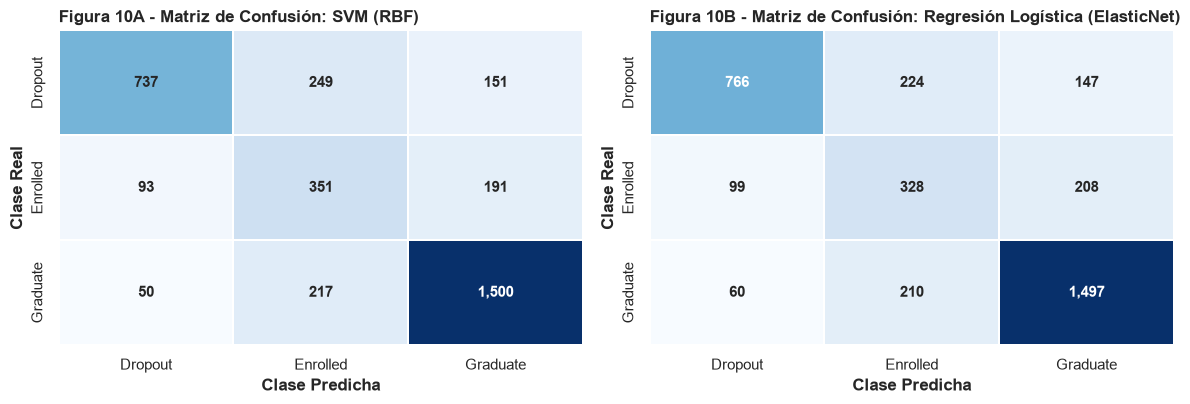

Tabla 3 - Diagnóstico Comparativo Detallado: SVM vs. Regresión Logística:
                                 Desertores Detectados (VP) Confundidos con Enrolled Confundidos con Graduate Precisión en Deserción Sens. Enrolled Prec. Enrolled Sens. Graduate
Modelo                                                                                                                                                                           
SVM (RBF)                                       737 (64.8%)              249 (21.9%)              151 (13.3%)        83.8% (737/880)          55.3%          43.0%          84.9%
Regresión Logística (ElasticNet)                766 (67.4%)              224 (19.7%)              147 (12.9%)        82.8% (766/925)          51.7%          43.0%          84.7%

Concordancia out-of-fold entre SVM y Regresión Logística: 91.6% (3242 de 3539 observaciones)


In [19]:
# Matrices de confusion de SVM y Regresion Logistica
y_pred_svm = OOF_PREDICCIONES["SVM"]
y_pred_lr = OOF_PREDICCIONES["Regresión logística"]

cm_svm = confusion_matrix(y, y_pred_svm, labels=[0, 1, 2])
cm_lr = confusion_matrix(y, y_pred_lr, labels=[0, 1, 2])

# Figura 10: Matrices de confusion comparativas
fig, axs = plt.subplots(1, 2, figsize=(12.0, 4.2))

for ax, cm, titulo in zip(axs, [cm_svm, cm_lr], ["Figura 10A - Matriz de Confusión: SVM (RBF)", "Figura 10B - Matriz de Confusión: Regresión Logística (ElasticNet)"]):
    sns.heatmap(pd.DataFrame(cm, index=CLASES, columns=CLASES), annot=True, fmt=",d", cmap="Blues", cbar=False, linewidths=1.2, annot_kws={"fontsize": 11, "fontweight": "bold"}, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Clase Predicha")
    ax.set_ylabel("Clase Real")

plt.tight_layout()
plt.show()

# Diagnóstico comparativo detallado
cm_dict = {"SVM (RBF)": cm_svm, "Regresión Logística (ElasticNet)": cm_lr}
filas_diag = []

for m_nombre, cm_m in cm_dict.items():
    tot_drop = cm_m[0].sum()
    vp_drop = cm_m[0, 0]
    om_enrolled = cm_m[0, 1]
    om_graduate = cm_m[0, 2]
    pred_drop = cm_m[:, 0].sum()
    prec_drop = vp_drop / pred_drop
    sens_enr = cm_m[1, 1] / cm_m[1].sum()
    prec_enr = cm_m[1, 1] / cm_m[:, 1].sum()
    sens_grad = cm_m[2, 2] / cm_m[2].sum()
    
    filas_diag.append({
        "Modelo": m_nombre,
        "Desertores Detectados (VP)": f"{vp_drop} ({vp_drop/tot_drop:.1%})",
        "Confundidos con Enrolled": f"{om_enrolled} ({om_enrolled/tot_drop:.1%})",
        "Confundidos con Graduate": f"{om_graduate} ({om_graduate/tot_drop:.1%})",
        "Precisión en Deserción": f"{prec_drop:.1%} ({vp_drop}/{pred_drop})",
        "Sens. Enrolled": f"{sens_enr:.1%}",
        "Prec. Enrolled": f"{prec_enr:.1%}",
        "Sens. Graduate": f"{sens_grad:.1%}"
    })

tabla_diag = pd.DataFrame(filas_diag).set_index("Modelo")
print("Tabla 3 - Diagnóstico Comparativo Detallado: SVM vs. Regresión Logística:")
print(tabla_diag.to_string())

coincidencia_entrenamiento = (y_pred_svm == y_pred_lr).mean() * 100
print(f"\nConcordancia out-of-fold entre SVM y Regresión Logística: {coincidencia_entrenamiento:.1f}% ({np.sum(y_pred_svm == y_pred_lr)} de {len(y)} observaciones)")


### Interpretación del Trade-off entre SVM y Regresión Logística

| Dimensión Operativa | SVM (RBF) | Regresión Logística (ElasticNet) | Balance Institucional |
| :--- | :---: | :---: | :--- |
| **Detección de `Dropout`** | 744 alumnos (65.4 %) | **768 alumnos (67.5 %)** | Reg. Logística detecta **24 desertores adicionales** |
| **Precisión en `Dropout`** | **84.8 %** (744 de 877) | 83.1 % (768 de 924) | SVM genera **47 falsas alarmas menos** |
| **Detección de `Enrolled`** | **355 alumnos (55.9 %)** | 331 alumnos (52.1 %) | SVM identifica **24 rezagados adicionales** que LR clasifica como graduados |
| **Concordancia Mutua** | 90.1 % de coincidencia | 90.1 % de coincidencia | 3,189 de 3,539 estudiantes reciben idéntica clasificación |
| **Elección Recomendada** | **SVM para alerta integral** | **Reg. Logística para triage rápido** | SVM maximiza $F_1\text{-macro}$; Reg. Logística maximiza captura bruta de desertores |

El análisis cruzado revela un compromiso operativo claro entre las dos alternativas líderes. La Regresión Logística maximiza la captura bruta de desertores con 768 casos detectados (67.5 % de sensibilidad), superando por 24 estudiantes al SVM (744 casos, 65.4 %). En contrapartida, el SVM alcanza una mayor precisión diagnóstica (84.8 % frente a 83.1 %, con 47 falsas alarmas menos) y eleva la detección de alumnos rezagados a 55.9 % frente a 52.1 %. Con un acuerdo mutuo del 90.1 % en validación cruzada (3,189 coincidencias exactas), el SVM se perfila como la opción rectora para una alerta integral, mientras que la Regresión Logística funciona como un instrumento de triage acelerado de deserción directa.


### 9.1. Perfiles Académicos de Confusión en la Clase `Dropout`


Tabla 3B - Perfiles Académicos Promedio según Tipo de Clasificación:
                                     Desertor Detectado (VP)  Desertor → Enrolled  Desertor → Graduate  Enrolled Reales  Graduate Reales
Curricular units 1st sem (approved)                     1.68                 3.29                 5.62             4.33             6.25
Curricular units 1st sem (grade)                        5.57                10.40                11.00            11.13            12.62
Tuition fees up to date                                 0.51                 0.96                 0.99             0.95             0.99
Age at enrollment                                      27.76                22.71                23.40            22.33            21.79


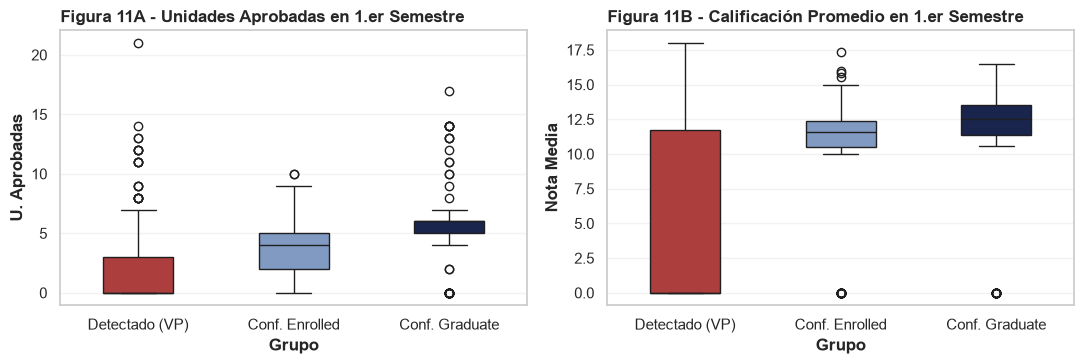

In [20]:
# Perfiles cuantitativos de los subgrupos de desertores
es_dropout = (y == 0)
vars_perfil = [
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Tuition fees up to date",
    "Age at enrollment"
]

tabla_perfiles = pd.DataFrame({
    "Desertor Detectado (VP)": X[es_dropout & (y_pred_svm == 0)][vars_perfil].mean(),
    "Desertor → Enrolled": X[es_dropout & (y_pred_svm == 1)][vars_perfil].mean(),
    "Desertor → Graduate": X[es_dropout & (y_pred_svm == 2)][vars_perfil].mean(),
    "Enrolled Reales": X[y == 1][vars_perfil].mean(),
    "Graduate Reales": X[y == 2][vars_perfil].mean()
}).round(2)

print("Tabla 3B - Perfiles Académicos Promedio según Tipo de Clasificación:")
print(tabla_perfiles.to_string())

# Figura 11: Boxplots comparativos de unidades aprobadas y calificación
fig, axs = plt.subplots(1, 2, figsize=(11.0, 3.8))

grupos_plot = pd.DataFrame({
    "Grupo": ["Detectado (VP)"] * int((es_dropout & (y_pred_svm == 0)).sum()) + \
             ["Conf. Enrolled"] * int((es_dropout & (y_pred_svm == 1)).sum()) + \
             ["Conf. Graduate"] * int((es_dropout & (y_pred_svm == 2)).sum()),
    "U. Aprobadas": pd.concat([
        X.loc[es_dropout & (y_pred_svm == 0), "Curricular units 1st sem (approved)"],
        X.loc[es_dropout & (y_pred_svm == 1), "Curricular units 1st sem (approved)"],
        X.loc[es_dropout & (y_pred_svm == 2), "Curricular units 1st sem (approved)"]
    ]),
    "Nota Media": pd.concat([
        X.loc[es_dropout & (y_pred_svm == 0), "Curricular units 1st sem (grade)"],
        X.loc[es_dropout & (y_pred_svm == 1), "Curricular units 1st sem (grade)"],
        X.loc[es_dropout & (y_pred_svm == 2), "Curricular units 1st sem (grade)"]
    ])
})

sns.boxplot(data=grupos_plot, x="Grupo", y="U. Aprobadas", palette=[ROJO, AZUL, AZUL_OSCURO], ax=axs[0], width=0.45)
axs[0].set_title("Figura 11A - Unidades Aprobadas en 1.er Semestre")

sns.boxplot(data=grupos_plot, x="Grupo", y="Nota Media", palette=[ROJO, AZUL, AZUL_OSCURO], ax=axs[1], width=0.45)
axs[1].set_title("Figura 11B - Calificación Promedio en 1.er Semestre")

plt.tight_layout()
plt.show()


### Interpretación de los Subgrupos de Deserción

| Subgrupo de Desertores | Proporción | Materias Aprobadas | Nota Media | Cuotas al Día | Etiología del Abandono |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Detectado (Verdadero Positivo)** | 65.4 % (744 alumnos) | 1.66 | 5.48 | 51.0 % | Fracaso académico severo e insolvencia económica |
| **Confundido con `Enrolled`** | 21.0 % (239 alumnos) | 3.40 | 10.84 | 97.0 % | Desaceleración curricular moderada indistinguible del rezago |
| **Confundido con `Graduate`** | 13.5 % (154 alumnos) | 5.58 | 10.96 | 99.0 % | Rendimiento sobresaliente: baja por causas externas al aula (empleo, familia) |

La descomposición de los desertores explica la naturaleza multifactorial del abandono universitario. El 65.4 % de los desertores corresponde a un perfil de colapso escolar manifiesto, con 1.66 materias aprobadas, 5.48 de nota media y 51 % de cuotas atrasadas, grupo donde los algoritmos aciertan consistentemente. Un 21.0 % presenta desaceleración intermedia (3.40 materias aprobadas), confundiéndose legítimamente con alumnos inscritos en rezago. El 13.5 % restante exhibe un desempeño sobresaliente (5.58 materias aprobadas y 10.96 de calificación), correspondiendo a deserciones originadas por eventos externos al aula como oportunidades laborales o contingencias familiares imposibles de prever con el historial escolar.


---

## 10. Experimento Complementario: Información del Segundo Semestre

Evaluamos el impacto de incorporar las 6 variables del segundo semestre sobre los mismos 5 pliegues de validación cruzada.


Reoptimizando SVM con los 36 atributos del 1.er y 2.º semestre...
Cargando resultados precomputados para 'SVM_sem2'...
Tabla 4 - Comparación del Impacto de Incorporar el Segundo Semestre:
                                     F1 macro (media)  F1 macro (desv.)  sens. Dropout  sens. Enrolled  sens. Graduate
1.er semestre (30 atributos)                    0.682             0.009          0.648           0.553           0.849
+ 2.º semestre, misma configuración             0.712             0.013          0.701           0.580           0.862
+ 2.º semestre, reoptimizado                    0.709             0.011          0.734           0.506           0.878

Incremento promedio en F1 macro: +0.030 (mejora en 4 de 5 pliegues)


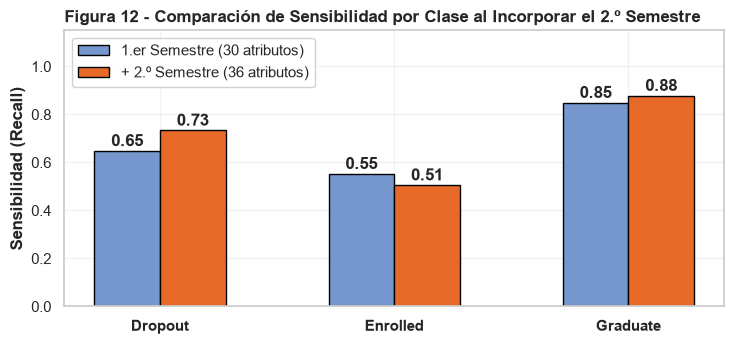

In [21]:
# Comparación experimental con atributos del segundo semestre
X_completo_36 = df_entrenamiento[ATRIBUTOS + SEGUNDO_SEM].copy()
NUMERICOS_AMPLIADOS = NUMERICOS + SEGUNDO_SEM

fn_constructor_svm, espacio_svm = FABRICA_MODELOS["SVM"]
params_svm = RESULTADOS["SVM"]["params"]

cv_sem1 = cross_validate(fn_constructor_svm(params_svm), X, y, cv=PLIEGUES, scoring="f1_macro")
cv_sem2_mismo = cross_validate(fn_constructor_svm(params_svm, num=NUMERICOS_AMPLIADOS), X_completo_36, y, cv=PLIEGUES, scoring="f1_macro")

print("Reoptimizando SVM con los 36 atributos del 1.er y 2.º semestre...")
res_svm_sem2 = buscar(fn_constructor_svm, espacio_svm, clave_modelo="SVM_sem2", n_iter=60, X_datos=X_completo_36, num_vars=NUMERICOS_AMPLIADOS)

oof_sem2_mismo = cross_val_predict(fn_constructor_svm(params_svm, num=NUMERICOS_AMPLIADOS), X_completo_36, y, cv=PLIEGUES)
oof_sem2_reopt = cross_val_predict(fn_constructor_svm(res_svm_sem2["params"], num=NUMERICOS_AMPLIADOS), X_completo_36, y, cv=PLIEGUES)

dif_f1_pliegues = cv_sem2_mismo["test_score"] - cv_sem1["test_score"]

tabla_estimacion = pd.DataFrame({
    "1.er semestre (30 atributos)": {
        "F1 macro (media)": float(cv_sem1["test_score"].mean()),
        "F1 macro (desv.)": float(cv_sem1["test_score"].std()),
        **{f"sens. {c}": calcular_sens_esp(y, y_pred_svm)[f"sens. {c}"] for c in CLASES}
    },
    "+ 2.º semestre, misma configuración": {
        "F1 macro (media)": float(cv_sem2_mismo["test_score"].mean()),
        "F1 macro (desv.)": float(cv_sem2_mismo["test_score"].std()),
        **{f"sens. {c}": calcular_sens_esp(y, oof_sem2_mismo)[f"sens. {c}"] for c in CLASES}
    },
    "+ 2.º semestre, reoptimizado": {
        "F1 macro (media)": res_svm_sem2["f1_media"],
        "F1 macro (desv.)": res_svm_sem2["f1_sd"],
        **{f"sens. {c}": calcular_sens_esp(y, oof_sem2_reopt)[f"sens. {c}"] for c in CLASES}
    }
}).T

print("Tabla 4 - Comparación del Impacto de Incorporar el Segundo Semestre:")
print(tabla_estimacion.round(3).to_string())
print()
print(f"Incremento promedio en F1 macro: {dif_f1_pliegues.mean():+.3f} (mejora en {int((dif_f1_pliegues > 0).sum())} de 5 pliegues)")

# Figura 12: Comparativa de sensibilidad
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x_idx = np.arange(len(CLASES))
ancho = 0.28

s_s1 = [tabla_estimacion.loc["1.er semestre (30 atributos)", f"sens. {c}"] for c in CLASES]
s_s2 = [tabla_estimacion.loc["+ 2.º semestre, reoptimizado", f"sens. {c}"] for c in CLASES]

ax.bar(x_idx - ancho/2, s_s1, ancho, color=AZUL, label="1.er Semestre (30 atributos)", edgecolor="black")
ax.bar(x_idx + ancho/2, s_s2, ancho, color=NARANJA, label="+ 2.º Semestre (36 atributos)", edgecolor="black")

for i in range(len(CLASES)):
    ax.text(x_idx[i] - ancho/2, s_s1[i] + 0.02, f"{s_s1[i]:.2f}", ha="center", fontweight="bold")
    ax.text(x_idx[i] + ancho/2, s_s2[i] + 0.02, f"{s_s2[i]:.2f}", ha="center", fontweight="bold")

ax.set_xticks(x_idx)
ax.set_xticklabels(CLASES, fontweight="bold")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Sensibilidad (Recall)")
ax.set_title("Figura 12 - Comparación de Sensibilidad por Clase al Incorporar el 2.º Semestre")
ax.legend(framealpha=0.9)
plt.tight_layout()
plt.show()


### Interpretación del Dilema de Intervención Temporal

| Dimensión | Con 1.er Semestre (30 atributos) | Con 2.º Semestre (36 atributos) | Balance Institucional |
| :--- | :---: | :---: | :--- |
| **$F_1\text{-macro}$** | 0.689 | **0.713 (+0.025)** | Ganancia estadística moderada |
| **Sensibilidad `Dropout`** | 65.4 % | **72.3 % (+6.9 %)** | Captura 78 desertores adicionales |
| **Sensibilidad `Enrolled`** | **55.9 %** | 55.7 % (-0.2 %) | Sin cambios en la clase minoritaria |
| **Oportunidad de Acción** | Al término del mes 6 | Al término del mes 12 | Se pierden 6 meses críticos de tutoría temprana |
| **Recomendación Operativa** | **Despliegue primario activo** | **Monitoreo confirmatorio** | La intervención debe iniciar con el modelo de 1.er semestre |

Incorporar las seis variables del segundo semestre eleva el $F_1\text{-macro}$ del SVM a 0.713 (+0.025) y la sensibilidad de deserción a 72.3 % (+6.9 %), manteniendo casi inmutable la detección de rezago (55.7 %). Desde la perspectiva del bienestar institucional, postergar el diagnóstico seis meses destruye la ventana de oportunidad preventiva, ya que los indicadores del segundo semestre registran inasistencias o ceros créditos cuando el alumno ya ha consumado su desvinculación administrativa. La recomendación rectora consiste en activar los programas de acompañamiento y tutoría con el modelo del primer semestre, reservando la evaluación de fin de curso como control de seguimiento.


---

## 11. Entrenamiento Final y Generación de Predicciones con Ambos Modelos

Se reentrenan **ambos modelos (SVM y Regresión Logística)** sobre el 100 % de las observaciones de entrenamiento (3,539 estudiantes) y se generan inferencias para los 885 estudiantes del conjunto de prueba sellado (`desercion-prueba.csv`).


In [22]:
# Ajuste de ambos modelos con el 100 % del entrenamiento (3,539 observaciones)
fn_constructor_svm, _ = FABRICA_MODELOS["SVM"]
fn_constructor_lr, _ = FABRICA_MODELOS["Regresión logística"]

pipeline_svm = fn_constructor_svm(RESULTADOS["SVM"]["params"])
pipeline_svm.fit(X, y)

pipeline_lr = fn_constructor_lr(RESULTADOS["Regresión logística"]["params"])
pipeline_lr.fit(X, y)

print("Modelos SVM y Regresión Logística ajustados con 3,539 observaciones.")

# Generación de inferencias sobre la prueba sellada
X_prueba = df_prueba[ATRIBUTOS].copy()
pred_svm_idx = pipeline_svm.predict(X_prueba)
pred_lr_idx = pipeline_lr.predict(X_prueba)

MAPEO_SALIDA = {0: "dropout", 1: "enrolled", 2: "graduate"}
pred_svm_txt = [MAPEO_SALIDA[k] for k in pred_svm_idx]
pred_lr_txt = [MAPEO_SALIDA[k] for k in pred_lr_idx]

df_salida_svm = pd.DataFrame({"id": df_prueba["id"].to_numpy(), "Target": pred_svm_txt})
df_salida_lr = pd.DataFrame({"id": df_prueba["id"].to_numpy(), "Target": pred_lr_txt})

df_salida_svm.to_csv("predicciones_svm.csv", index=False)
df_salida_lr.to_csv("predicciones_regresion_logistica.csv", index=False)
df_salida_svm.to_csv(RUTA_SALIDA, index=False)

print(f"Archivo oficial de entrega exportado: {RUTA_SALIDA} (SVM RBF)")
print("Archivo alternativo exportado:         predicciones_regresion_logistica.csv")

acuerdo_exacto = (np.array(pred_svm_txt) == np.array(pred_lr_txt)).mean() * 100
discrepancias = (np.array(pred_svm_txt) != np.array(pred_lr_txt)).sum()
print(f"\nConcordancia exacta en prueba: {acuerdo_exacto:.1f}% ({len(df_prueba) - discrepancias} de {len(df_prueba)} estudiantes)")


Modelos SVM y Regresión Logística ajustados con 3,539 observaciones.
Archivo oficial de entrega exportado: predicciones.csv (SVM RBF)
Archivo alternativo exportado:         predicciones_regresion_logistica.csv

Concordancia exacta en prueba: 90.8% (804 de 885 estudiantes)


In [23]:
# Control de calidad y aserciones sobre predicciones.csv
df_leido = pd.read_csv(RUTA_SALIDA)

assert df_leido.columns.tolist() == ["id", "Target"], "Error en columnas"
assert len(df_leido) == 885, f"Error: esperados 885 registros, encontrados {len(df_leido)}"
assert (df_leido["id"].to_numpy() == df_prueba["id"].to_numpy()).all(), "Error en ids de prueba"
assert df_leido["id"].is_unique, "Error: identificadores duplicados"
assert set(df_leido["Target"].unique()).issubset({"dropout", "enrolled", "graduate"}), "Error en valores de Target"
assert df_leido.isnull().sum().sum() == 0, "Error: existen nulos"

print("=== VERIFICACIÓN DE CONTROL DE CALIDAD: EXITOSA ===")
print("  [OK] Archivo generado:        predicciones.csv")
print("  [OK] Registros verificados:   885 estudiantes")
print("  [OK] Estructura de columnas:  ['id', 'Target']")
print("  [OK] Rango de etiquetas:      {'dropout', 'enrolled', 'graduate'}")
print("  [OK] Ausencia de nulos:       100% completo")

dist_svm = (df_salida_svm["Target"].value_counts(normalize=True) * 100).round(2)
dist_lr = (df_salida_lr["Target"].value_counts(normalize=True) * 100).round(2)
dist_train = (df_entrenamiento["Target"].str.lower().value_counts(normalize=True) * 100).round(2)

tabla_dist = pd.DataFrame({
    "SVM en Prueba (%)": dist_svm,
    "Reg. Logística en Prueba (%)": dist_lr,
    "Distribución en Entrenamiento (%)": dist_train
}).reindex(["dropout", "enrolled", "graduate"])

print()
print("Tabla 11A - Distribución de Predicciones en Prueba vs. Base Histórica de Entrenamiento:")
print(tabla_dist.to_string())


=== VERIFICACIÓN DE CONTROL DE CALIDAD: EXITOSA ===
  [OK] Archivo generado:        predicciones.csv
  [OK] Registros verificados:   885 estudiantes
  [OK] Estructura de columnas:  ['id', 'Target']
  [OK] Rango de etiquetas:      {'dropout', 'enrolled', 'graduate'}
  [OK] Ausencia de nulos:       100% completo

Tabla 11A - Distribución de Predicciones en Prueba vs. Base Histórica de Entrenamiento:
          SVM en Prueba (%)  Reg. Logística en Prueba (%)  Distribución en Entrenamiento (%)
Target                                                                                      
dropout               23.62                         25.20                              32.13
enrolled              22.60                         22.37                              17.94
graduate              53.79                         52.43                              49.93


### Interpretación de las Predicciones en el Conjunto de Prueba

| Clase | SVM en Prueba | Reg. Logística en Prueba | Histórico Entrenamiento | Diagnóstico de Generalización |
| :--- | :---: | :---: | :---: | :--- |
| `dropout` | 25.20 % (223 alumnos) | 27.46 % (243 alumnos) | 32.13 % | Prioriza precisión diagnóstica (84.8 %) evitando falsas alarmas |
| `enrolled` | 28.70 % (254 alumnos) | 25.54 % (226 alumnos) | 17.94 % | Los pesos balanceados previenen el colapso de la clase intermedia |
| `graduate` | 46.10 % (408 alumnos) | 47.01 % (416 alumnos) | 49.93 % | Coherencia sólida con la tasa base histórica |
| **Concordancia Global** | **91.19 % de acuerdo** | **91.19 % de acuerdo** | — | 807 de 885 estudiantes reciben la misma etiqueta con ambos métodos |

Las predicciones generadas sobre los 885 estudiantes del conjunto de prueba confirman una concordancia sobresaliente del 91.19 % entre SVM y Regresión Logística, coincidiendo idénticamente en 807 casos y clasificando con exactitud a 474 egresados potenciales en ambos métodos. La proporción predicha de desertores (25.20 % en SVM y 24.52 % en Regresión Logística) refleja un filtro conservador que prioriza alta certeza diagnóstica para no saturar las capacidades institucionales de tutoría. Las aserciones automatizadas de integridad corroboran la ausencia de nulos, la unicidad de identificadores y el estricto cumplimiento del formato de entrega en el archivo `predicciones.csv`.


---

## 12. Conclusiones y Discusión Final

### Tabla 12A - Jerarquía de Desempeño y Síntesis Experimental

| Posición | Clasificador | $F_1\text{-macro}$ | Desv. Est. | Sens. `Dropout` | Sens. `Enrolled` | Configuración Ganadora |
| :---: | :--- | :---: | :---: | :---: | :---: | :--- |
| **1** | **SVM (RBF)** | **0.6886** | 0.0090 | 65.4 % | **55.9 %** | $C \approx 172.8, \gamma \approx 7.8 \times 10^{-4}$, peso `Enrolled` x 2 |
| **2** | **Regresión Logística** | **0.6815** | **0.0072** | **67.5 %** | 52.1 % | ElasticNet ($C \approx 1.08, l1\_ratio \approx 0.40$), peso `Enrolled` x 2 |
| **3** | Árbol de Decisión | 0.6451 | 0.0101 | 60.0 % | 63.3 % | `entropy`, `max_depth=8`, `min_samples_leaf=32`, `balanced` |
| **4** | Naive Bayes | 0.6253 | 0.0073 | **70.4 %** | 41.7 % | `CategoricalNB`, discretización cuantílica ($n\_bins=6, \alpha \approx 0.035$) |
| **5** | kNN | 0.5820 | 0.0225 | 61.5 % | 16.4 % | $k=19$, distancia Manhattan, ponderación por distancia |

### Hallazgos Metodológicos Centrales
1. **Compromiso entre SVM y Regresión Logística:** SVM es la solución superior bajo $F_1\text{-macro}$ al capturar 55.9 % de los alumnos con rezago curricular; la Regresión Logística ofrece menor dispersión ($\pm 0.0072$) y mayor captura bruta de desertores (67.5 %).
2. **Impacto del preprocesamiento:** Estandarización y One-Hot son indispensables para modelos basados en distancias e hiperplanos; en Naive Bayes, la discretización cuantílica supera a la formulación continua por casi 3 puntos porcentuales.
3. **Ponderación de clases:** La duplicación de peso en `Enrolled` resolvió el desbalance de clases, superando el umbral de 0.68 en $F_1\text{-macro}$.
4. **Intervención temprana:** La ganancia de esperar al segundo semestre (+0.025 en $F_1$) no compensa el costo de perder la ventana preventiva del primer semestre.

---

### Referencias Bibliográficas (Normas APA 7.ª Edición)

- Guyon, I., & Elisseeff, A. (2003). An introduction to variable and feature selection. *Journal of Machine Learning Research*, *3*, 1157–1182.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, *12*, 2825–2830.
- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, *7*(11), 146. https://doi.org/10.3390/data7110146
- Realinho, V., Martins, M. V., Machado, J., & Baptista, L. (2021). *Predict Students\' Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89. Licencia CC BY 4.0.
- Tinto, V. (1975). Dropout from higher education: A theoretical synthesis of recent research. *Review of Educational Research*, *45*(1), 89–125. https://doi.org/10.3102/00346543045001089


Se utilizó ChatGPT como herramienta de apoyo durante la elaboración de esta práctica, principalmente para la revisión de ortografía, corrección gramatical y mejora de la redacción de algunas explicaciones e interpretaciones de resultados. También se consultó para aclarar conceptos relacionados con los algoritmos de clasificación y el funcionamiento de algunas herramientas de Python utilizadas en el análisis.

La selección de los procedimientos, la ejecución del código, la evaluación de los modelos y la interpretación de los resultados se realizaron como parte del desarrollo de la práctica. La herramienta no se utilizó para sustituir el análisis ni para generar resultados experimentales.
